# Wine Clustering: Finding Wine Styles without Labels

A wine shop receives lab measurements for 178 wines (alcohol, acidity, phenols, colour …) but nobody wrote down what *kind* of wine each one is. Can the numbers alone sort them into styles that make sense on a shelf? This notebook groups the wines with four families of clustering, checks how stable the groups are, describes each style in plain words, and only at the end opens the hidden answer key (the grape variety) to see how close the unsupervised groups came.

**Objectives**
1. Which measurements need fixing before distances mean anything?
2. How many natural groups are there?
3. Which clustering family fits these wines best, and are its groups stable?
4. What makes each group different, in words a wine seller can use?
5. Do the groups match the real grape varieties?

**Data** → [Wine Dataset for Clustering](https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering) · 178 wines × 13 lab measurements · same wines as the UCI wine data (3 grape varieties, hidden here)

<!-- objective -->
## Objective

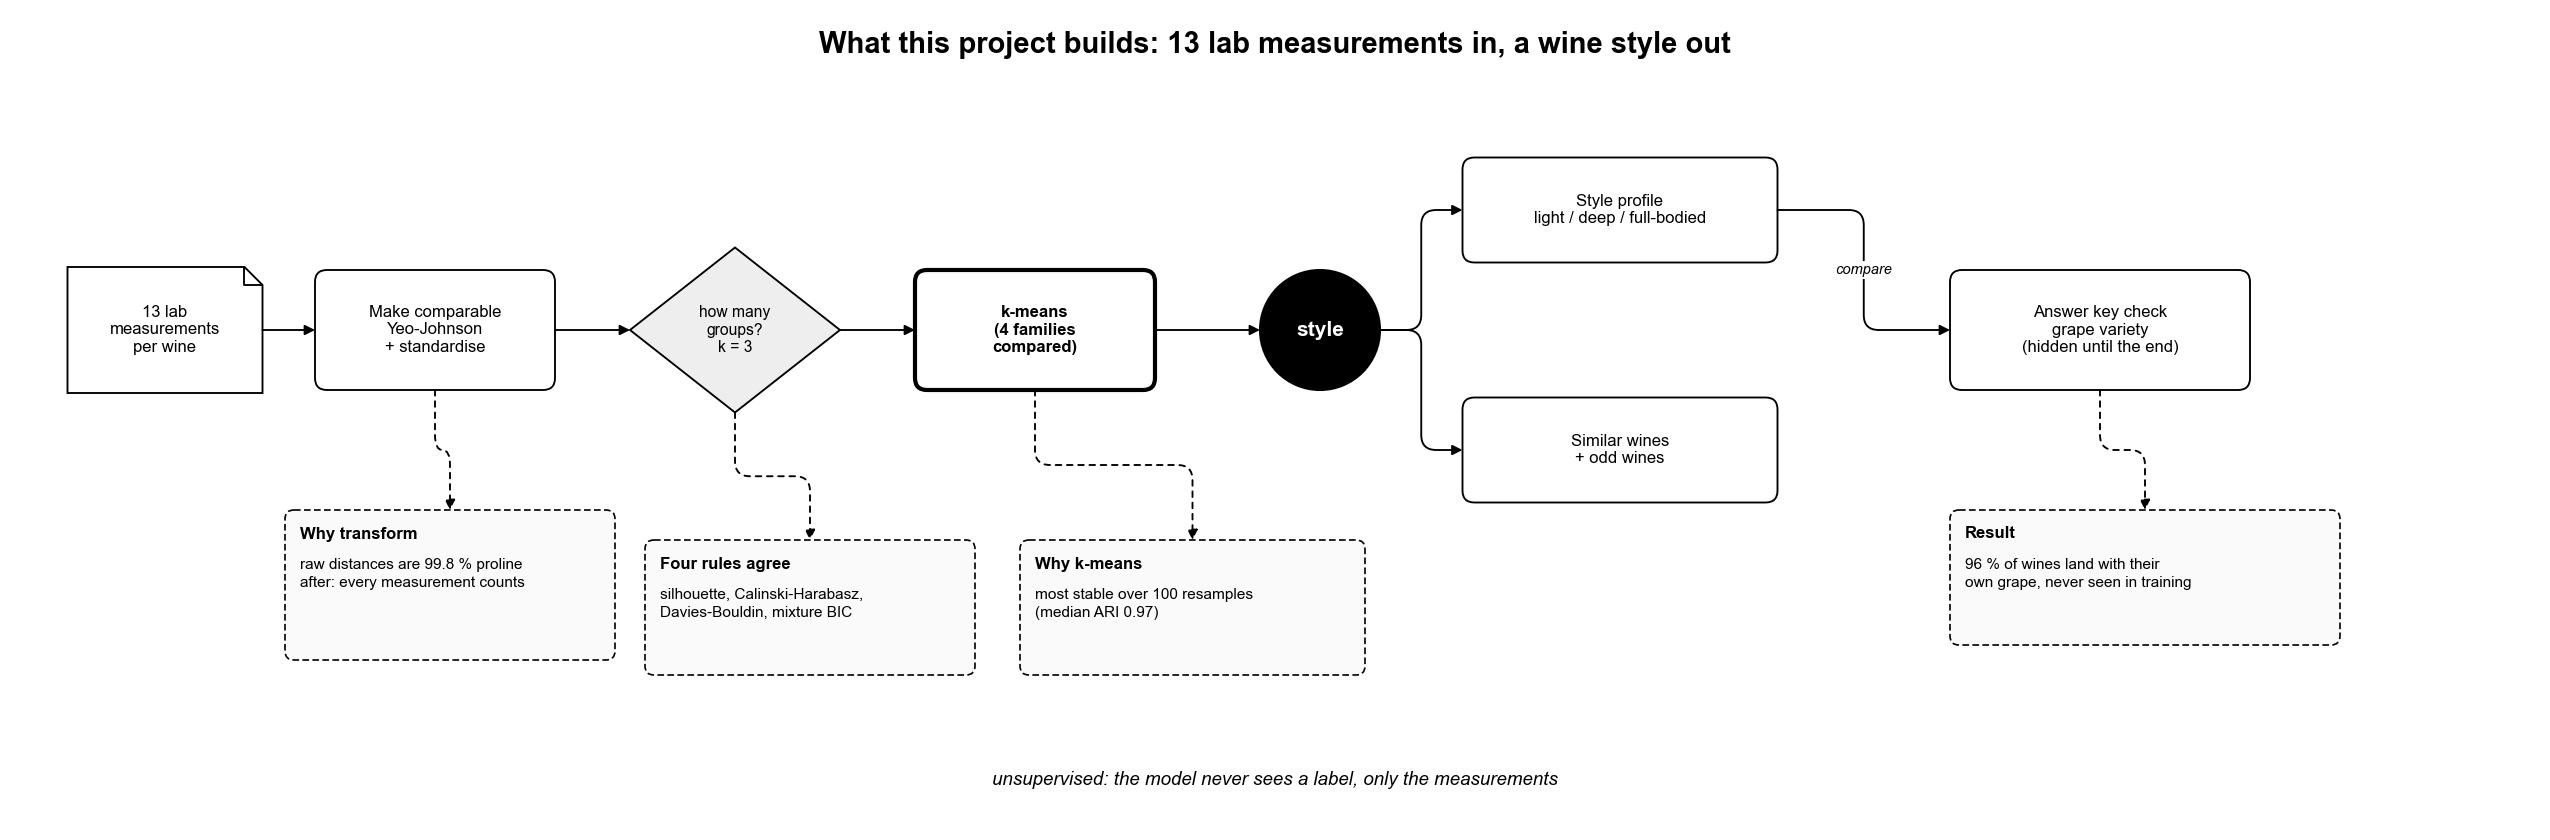

- **Problem** → a shop or distributor has lab sheets for its wines but no agreed "style" labels, so shelves, menus and "if you liked this" suggestions are guesswork
- **Why this repo** → group the wines from their chemistry alone, check that the groups are stable, describe each group in plain words, and only then compare with the real grape varieties
- **Real-world use** → shelf and menu categories, "similar wines" suggestions, and a flag for wines that fit no style (a lab re-check or a special shelf)

# [1/12] Setup

Set every knob once in the top cell → nothing is written and no app is started unless you switch it on

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/9] DATA_DIR: folder searched recursively for the wine CSV (falls back to /kaggle/input)
    Default = '/kaggle/input'
[2/9] WORK_DIR: folder for exported figures
    Default = '/kaggle/working'
[3/9] TRANSFORM: how each measurement is reshaped before distances are computed
    Default = 'yeo-johnson'
    For example:
        TRANSFORM = 'standard'
[4/9] K_MAX: largest number of groups tried
    Default = 10
[5/9] K_FINAL: number of groups used after section 7 (None = the k chosen by the silhouette score)
    Default = None
[6/9] N_BOOT: bootstrap resamples for the stability check
    Default = 100
[7/9] DBSCAN_MIN_SAMPLES: minimum neighbours for a DBSCAN core point
    Default = 5
[8/9] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
[9/9] LAUNCH_APP: start the Gradio style finder at the end (public link on Kaggle)
    Default = False
"""
DATA_DIR           = '/kaggle/input'
WORK_DIR           = '/kaggle/working'
TRANSFORM          = 'yeo-johnson'
K_MAX              = 10
K_FINAL            = None
N_BOOT             = 100
DBSCAN_MIN_SAMPLES = 5
SAVE_FIGURES       = False
LAUNCH_APP         = False

SEED               = 42
PAD                = 34
GREYS              = ['#000000', '#808080', '#c0c0c0', '#404040', '#a0a0a0', '#606060']

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from scipy.stats import skew
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, confusion_matrix, davies_bouldin_score,
                             silhouette_samples, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_wine_csv(*roots):
    """First CSV under the roots whose header has the wine measurements."""
    import csv
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        for f in sorted(root.rglob('*.csv')):
            with open(f, newline='', encoding='utf-8', errors='ignore') as fh:
                header = next(csv.reader(fh), [])
            if {'Proline', 'Flavanoids', 'Hue'} <= set(header):
                return f
    raise FileNotFoundError('(!) No wine CSV found. Add Input -> Datasets -> harrywang/wine-dataset-for-clustering')


def make_transform(kind=TRANSFORM):
    return make_pipeline(PowerTransformer(method='yeo-johnson')) if kind == 'yeo-johnson' else make_pipeline(StandardScaler())


def internal_scores(X, labels):
    mask = labels >= 0
    if len(set(labels[mask])) < 2:
        return {'silhouette': np.nan, 'Calinski-Harabasz': np.nan, 'Davies-Bouldin': np.nan}
    return {'silhouette': silhouette_score(X[mask], labels[mask]),
            'Calinski-Harabasz': calinski_harabasz_score(X[mask], labels[mask]),
            'Davies-Bouldin': davies_bouldin_score(X[mask], labels[mask])}

# [2/12] Data

Load the 178 wines → 13 numeric lab measurements, no label column

In [ ]:
csv_path = find_wine_csv(DATA_DIR, '/kaggle/input')
wine = pd.read_csv(csv_path)
FEATURES = list(wine.columns)
show_block('Outputs', {'file': csv_path.name, 'wine': wine.shape, 'missing values': int(wine.isna().sum().sum())})

In [ ]:
display(wine.describe().T.round(2))

**Question:** What does one row say?

One wine, 13 chemical measurements from the same lab: alcohol (%), malic acid, ash and its alkalinity, magnesium (mg/L), total phenols, flavanoids, non-flavanoid phenols, proanthocyanins, colour intensity, hue, OD280/OD315 (a protein / phenol absorbance ratio) and proline (an amino acid, mg/L).

**Answer:** 178 wines × 13 measurements, no missing values, and very different scales: proline runs 278-1,680 mg/L, hue 0.48-1.71.

# [3/12] Data health

Check gaps, skew and extreme values → decide what to fix before measuring distances

**Question:** Are the measurements ready to be compared with a distance?

$$\text{skewness} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i - \bar x}{s}\right)^3$$
- 0 → symmetric; > 1 → a long right tail that will dominate squared distances
- an IQR outlier lies more than 1.5 × IQR beyond the quartiles
- Analogy → comparing house prices and room counts on one ruler: the price column decides everything

**Answer:** clean, but not comparable yet.
- proline's std is 315, hue's 0.23 → proline alone holds 99.8 % of the raw variance
- mild skew (magnesium 1.09, malic acid 1.03); 21 IQR outliers over 7 measurements are real wines → kept

In [ ]:
q1, q3 = wine.quantile(0.25), wine.quantile(0.75)
iqr = q3 - q1
health = pd.DataFrame({'min': wine.min(), 'max': wine.max(), 'std': wine.std(),
                       'skewness': wine.apply(lambda c: skew(c)),
                       'IQR outliers': ((wine < q1 - 1.5 * iqr) | (wine > q3 + 1.5 * iqr)).sum()})

In [ ]:
display(health.round(2).sort_values('std', ascending=False))

# [4/12] EDA

Look at every distribution and the correlations → which measurements carry the same information

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(22, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(wine[col], bins=20, kde=True, color='grey', ax=ax)
    ax.set_title(f'{col}  (skew {skew(wine[col]):.2f})')
    ax.set_xlabel('')
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis('off')
fig.suptitle('Distribution of every measurement', fontweight='bold')
fig.tight_layout()
save(fig, '01_distributions')
plt.show()

In [ ]:
corr = wine.corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap='Greys', annot=True, fmt='.2f', annot_kws={'size': 8}, vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation between measurements')
save(fig, '02_correlation')
plt.show()

In [ ]:
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename('rho').reset_index()
         .assign(abs_rho=lambda d: d['rho'].abs()).sort_values('abs_rho', ascending=False).head(6))
display(pairs.drop(columns='abs_rho').round(3))

**Question:** Which measurements tell the same story?

$$\rho_s = 1 - \frac{6\sum d_i^2}{n(n^2 - 1)}$$
- $d_i$ → difference in rank of wine $i$ on the two measurements; ranks make it robust to skew and outliers
- $|\rho_s| > 0.7$ → largely the same information
- Analogy → two thermometers in one room: the second one adds little

**Answer:** the phenol family: total phenols and flavanoids (ρ 0.88), flavanoids and OD280 (0.74), flavanoids and proanthocyanins (0.73) → one "body" signal measured four ways. Alcohol rises with colour intensity (0.64).

# [5/12] Scaling

Cluster the raw numbers and the transformed numbers → raw distances are decided by one measurement

**Question:** What goes wrong if we cluster the raw numbers?

$$d(a, b) = \sqrt{\sum_{j=1}^{13} (x_{aj} - x_{bj})^2}$$
- Euclidean distance adds squared differences, so a column measured in hundreds (proline) outweighs one measured in tenths (hue)
- **Yeo-Johnson** → a power transform that makes each column close to normal, then mean 0 and std 1
- Analogy → converting every currency to one before adding up a bill

**Answer:** raw clusters are just proline clusters.
- raw k-means is identical to k-means on proline alone (ARI 1.00)
- after Yeo-Johnson the agreement drops to 0.36: every measurement has a say, and mean |skewness| falls from 0.43 to 0.04

In [ ]:
transformer = make_transform()
X = transformer.fit_transform(wine)
X_std = StandardScaler().fit_transform(wine)

km_raw = KMeans(3, n_init=20, random_state=SEED).fit_predict(wine)
km_proline = KMeans(3, n_init=20, random_state=SEED).fit_predict(wine[['Proline']])
km_scaled = KMeans(3, n_init=20, random_state=SEED).fit_predict(X)
share = (wine['Proline'].var() / wine.var().sum())
scaling = pd.DataFrame({
    'raw numbers': {'agreement with "proline only" (ARI)': adjusted_rand_score(km_proline, km_raw)},
    f'{TRANSFORM}': {'agreement with "proline only" (ARI)': adjusted_rand_score(km_proline, km_scaled)}})
skew_after = pd.Series(skew(X), index=FEATURES)

In [ ]:
show_block('Outputs', {'proline share of total variance (raw)': f'{share:.1%}',
                       'mean |skewness| before': f'{health["skewness"].abs().mean():.2f}',
                       f'mean |skewness| after {TRANSFORM}': f'{skew_after.abs().mean():.2f}'})
display(scaling.round(3))

# [6/12] PCA: a map of the wines

Compress 13 measurements into a few directions → a 2-D map to look at, and the measurements that spread the wines most

**Question:** How many directions are really needed to describe the wines?

$$\text{explained variance of PC}_k = \frac{\lambda_k}{\sum_{j} \lambda_j}$$
- $\lambda_k$ → variance along the $k$-th principal component (an eigenvalue of the correlation matrix)
- loadings → how much each measurement contributes to a component
- Analogy → photographing a 3-D object from the angle that shows the most

**Answer:** five for 80 % of the variance, two for a useful map (56 %).
- PC1 = the phenol family (flavanoids, total phenols, OD280)
- PC2 = colour intensity, alcohol and proline

In [ ]:
pca = PCA(random_state=SEED).fit(X)
P = pca.transform(X)
explained = pd.Series(pca.explained_variance_ratio_, index=[f'PC{i + 1}' for i in range(len(FEATURES))])
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2'])

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
axes[0].bar(explained.index, explained.values, color='grey')
axes[0].plot(explained.index, explained.cumsum().values, color='black', marker='o', label='cumulative')
axes[0].set(title='Explained variance', ylim=(0, 1.05))
axes[0].legend()
axes[0].tick_params(axis='x', rotation=90)
axes[1].scatter(P[:, 0], P[:, 1], s=25, color='black', alpha=0.7)
axes[1].set(title='Wines on the first two components', xlabel=f'PC1 ({explained.iloc[0]:.0%})', ylabel=f'PC2 ({explained.iloc[1]:.0%})')
order = loadings['PC1'].abs().sort_values().index
axes[2].barh(order, loadings.loc[order, 'PC1'], color='black', label='PC1')
axes[2].barh(order, loadings.loc[order, 'PC2'], color='grey', alpha=0.6, label='PC2')
axes[2].set(title='Loadings')
axes[2].legend()
fig.tight_layout()
save(fig, '03_pca')
plt.show()

In [ ]:
show_block('Outputs', {'PC1 + PC2': f'{explained.iloc[:2].sum():.1%}',
                       'components for 80 %': int((explained.cumsum() < 0.8).sum() + 1),
                       'top PC1 measurements': ', '.join(loadings['PC1'].abs().sort_values(ascending=False).index[:3]),
                       'top PC2 measurements': ', '.join(loadings['PC2'].abs().sort_values(ascending=False).index[:3])})

# [7/12] How many groups?

Score k = 2 … `K_MAX` with four rules → pick the k they agree on

**Question:** How many natural wine groups are there?

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$
- $a(i)$ → mean distance from wine $i$ to its own group, $b(i)$ → to the nearest other group; $s$ near 1 = well placed, near 0 = on a border
- also: **elbow** (inertia), **Calinski-Harabasz** (between / within spread, higher = better), **Davies-Bouldin** (lower = better), **BIC** of a Gaussian mixture (lower = better)
- Analogy → seating guests at tables: good tables are tight inside and far from each other

**Answer:** three. Silhouette (0.30), Calinski-Harabasz (73), Davies-Bouldin (1.36) and the mixture's BIC all pick k = 3. A silhouette of 0.30 means the groups touch rather than sit far apart.

In [ ]:
rows = []
for k in range(2, K_MAX + 1):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    gm = GaussianMixture(k, covariance_type='diag', n_init=5, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_, **internal_scores(X, km.labels_), 'GMM BIC': gm.bic(X)})
k_scores = pd.DataFrame(rows).set_index('k')
K = K_FINAL or int(k_scores['silhouette'].idxmax())

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(26, 4.5))
for ax, col in zip(axes, k_scores.columns):
    ax.plot(k_scores.index, k_scores[col], color='black', marker='o')
    ax.axvline(K, color='grey', linestyle='--')
    ax.set(title=col, xlabel='k')
fig.suptitle(f'Choosing the number of groups (dashed line: k = {K})', fontweight='bold')
fig.tight_layout()
save(fig, '04_choose_k')
plt.show()

In [ ]:
display(k_scores.round(3))
show_block('Outputs', {'k by silhouette': int(k_scores['silhouette'].idxmax()),
                       'k by Calinski-Harabasz': int(k_scores['Calinski-Harabasz'].idxmax()),
                       'k by Davies-Bouldin': int(k_scores['Davies-Bouldin'].idxmin()),
                       'k by GMM BIC': int(k_scores['GMM BIC'].idxmin()), 'k used': K})

# [8/12] Four families of clustering

Run one model from each family with k = `K` → compare how well each separates the wines

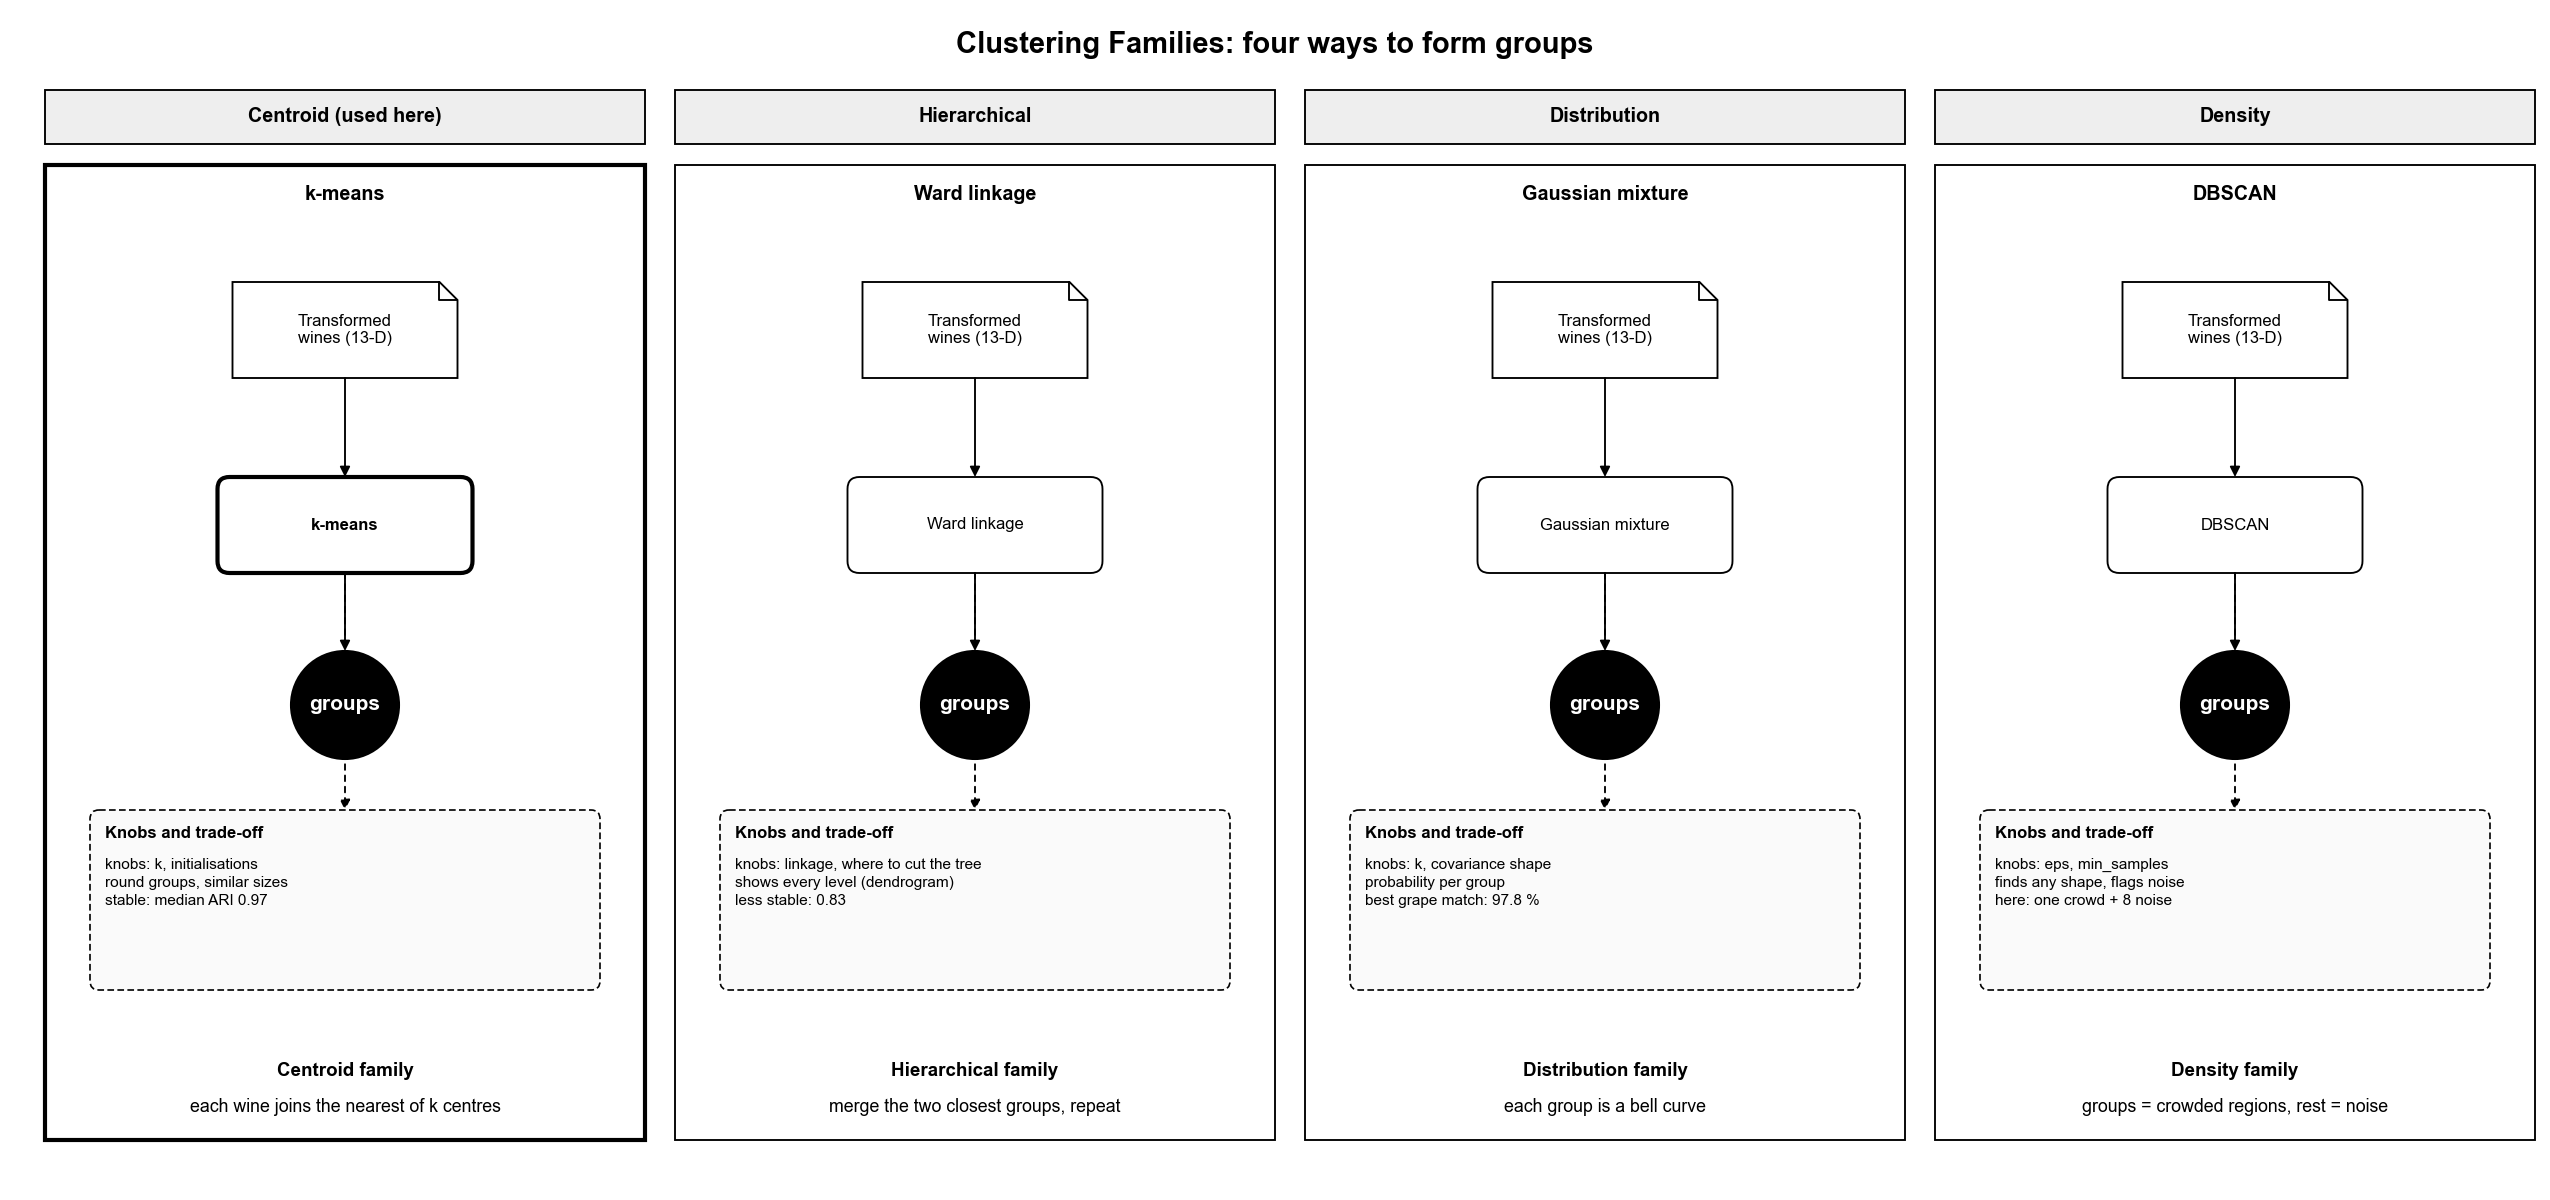

**Question:** Which family fits these wines best?

- **Centroid** (k-means) → each wine joins the nearest of k centres; round groups of similar size
- **Hierarchical** (Ward) → merge the two closest groups again and again; the dendrogram shows every level
- **Distribution** (Gaussian mixture) → each group is a bell curve; every wine gets a probability per group
- **Density** (DBSCAN) → groups are crowded regions; wines in empty space become noise
- Analogy → four ways to form teams: nearest captain, best friends merge, most likely club, who stands in a crowd

**Answer:** the three model-based families tie; density fails.
- silhouette: k-means 0.301, Gaussian mixture 0.297, Ward 0.290
- DBSCAN finds one crowd and 8 noise wines: in 13 dimensions there are no empty gaps to cut along

In [ ]:
eps_k = np.sort(NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
DBSCAN_EPS = float(np.quantile(eps_k, 0.90))

models = {
    'k-means': KMeans(K, n_init=50, random_state=SEED),
    'Ward hierarchical': AgglomerativeClustering(K, linkage='ward'),
    'Gaussian mixture': GaussianMixture(K, covariance_type='diag', n_init=10, random_state=SEED),
    'DBSCAN': DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES),
}
labels = {name: m.fit_predict(X) for name, m in models.items()}
family = pd.DataFrame({name: {'groups': len(set(l[l >= 0])), 'noise wines': int((l < 0).sum()), **internal_scores(X, l)}
                       for name, l in labels.items()}).T

In [ ]:
display(family.round(3))

In [ ]:
tsne = TSNE(2, perplexity=30, random_state=SEED).fit_transform(X)
fig, axes = plt.subplots(2, 4, figsize=(24, 11))
for col, (name, lab) in enumerate(labels.items()):
    for row, emb in enumerate([P[:, :2], tsne]):
        ax = axes[row, col]
        for g in sorted(set(lab)):
            m = lab == g
            ax.scatter(emb[m, 0], emb[m, 1], s=28, color='white' if g < 0 else GREYS[g % len(GREYS)],
                       edgecolor='black', linewidth=0.5, label='noise' if g < 0 else f'group {g}')
        ax.set_title(f'{name} · {"PCA" if row == 0 else "t-SNE"}')
        ax.legend(fontsize=8)
fig.suptitle('The same wines, grouped by four families (top: PCA map, bottom: t-SNE map)', fontweight='bold')
fig.tight_layout()
save(fig, '05_families')
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 5))
dendrogram(linkage(X, 'ward'), ax=axes[0], color_threshold=0, above_threshold_color='black', no_labels=True)
axes[0].set(title='Ward dendrogram: cutting at the largest vertical gap gives the groups', ylabel='merge distance')
axes[1].plot(eps_k, color='black')
axes[1].axhline(DBSCAN_EPS, color='grey', linestyle='--', label=f'eps = {DBSCAN_EPS:.2f} (90th percentile)')
axes[1].set(title=f'DBSCAN: distance to the {DBSCAN_MIN_SAMPLES}th neighbour, sorted', xlabel='wines', ylabel='distance')
axes[1].legend()
fig.tight_layout()
save(fig, '06_dendrogram_dbscan')
plt.show()

# [9/12] Stability

Re-fit every family on bootstrap resamples → a good grouping comes back almost unchanged

**Question:** Would the groups survive a slightly different set of wines?

$$\text{ARI} = \frac{\text{RI} - \mathbb{E}[\text{RI}]}{\max(\text{RI}) - \mathbb{E}[\text{RI}]}$$
- RI → share of wine pairs on which two groupings agree (same group / different group)
- ARI → 1 = identical groupings, 0 = no better than random labels
- each resample: fit on 178 wines drawn with replacement, give every wine the nearest resample-group centre, compare with the full-data grouping
- Analogy → asking a second panel of tasters: a real style is named again

**Answer:** k-means is the most stable (median ARI 0.97 over 100 resamples), then the Gaussian mixture (0.91) and Ward (0.83); DBSCAN never finds two groups → k-means is used for the profiles.

In [ ]:
def nearest_centre(X_fit, lab_fit, X_all):
    groups = sorted(set(lab_fit[lab_fit >= 0]))
    centres = np.stack([X_fit[lab_fit == g].mean(axis=0) for g in groups])
    return np.array(groups)[np.argmin(((X_all[:, None, :] - centres[None]) ** 2).sum(axis=2), axis=1)]


rng = np.random.default_rng(SEED)
stability = {name: [] for name in models}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(X), len(X))
    for name, model in models.items():
        lab = model.fit_predict(X[idx])
        if len(set(lab[lab >= 0])) < 2:
            stability[name].append(0.0)
            continue
        stability[name].append(adjusted_rand_score(labels[name], nearest_centre(X[idx], lab, X)))
stability = pd.DataFrame(stability)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=stability, color='lightgrey', ax=ax)
ax.set(title=f'Stability over {N_BOOT} bootstrap resamples (ARI with the full-data grouping)', ylabel='ARI', ylim=(-0.05, 1.05))
save(fig, '07_stability')
plt.show()
display(stability.describe().T[['mean', '25%', '50%', '75%']].round(3))

# [10/12] What makes each group different?

Describe the chosen grouping in original units → give every group a name a wine seller can use

In [ ]:
best_name = family.drop(index='DBSCAN')['silhouette'].idxmax()
groups = labels[best_name]
z = pd.DataFrame(StandardScaler().fit_transform(wine), columns=FEATURES)
centres_z = z.groupby(groups).mean()


def style_name(row):
    top = row.abs().sort_values(ascending=False).index[:2]
    return ' · '.join(f'{"high" if row[c] > 0 else "low"} {c.lower().replace("_", " ")}' for c in top)


STYLE = {g: f'Style {chr(65 + i)}: {style_name(centres_z.loc[g])}' for i, g in enumerate(centres_z.index)}
profile = wine.groupby(groups).mean().T.round(2)
profile.columns = [STYLE[g].split(':')[0] for g in profile.columns]
profile['spread (std)'] = wine.std().round(2)

In [ ]:
show_block('Outputs', {'model used': best_name, **{STYLE[g]: f'{(groups == g).sum()} wines' for g in sorted(STYLE)}})
display(profile)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 6), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(centres_z.T, cmap='Greys', center=0, annot=True, fmt='.1f', ax=axes[0],
            xticklabels=[STYLE[g].split(':')[0] for g in centres_z.index])
axes[0].set_title('Group centres in standard deviations from the average wine')
key = centres_z.abs().max().sort_values(ascending=False).index[:4]
long = z[key].assign(style=[STYLE[g].split(':')[0] for g in groups]).melt(id_vars='style')
sns.violinplot(data=long, x='variable', y='value', hue='style', hue_order=sorted(long['style'].unique()),
               palette='Greys', ax=axes[1], cut=0)
axes[1].set(title='The four measurements that separate the groups most', xlabel='', ylabel='z-score')
fig.tight_layout()
save(fig, '08_profiles')
plt.show()

**Question:** How would a wine seller describe each group?

- each group is named by its two most extreme measurements (in standard deviations from the average wine)
- flavanoids, total phenols and OD280 → body, bitterness and ageing potential; colour intensity and hue → how deep and how brown-red the wine looks; proline → typical of fuller, riper wines
- Analogy → describing three friends by what stands out most, not by every detail

**Answer:** three easy-to-explain styles.
- **A, light** (64 wines) → 12.3 % alcohol, pale colour (3.0), little proline (505)
- **B, deep and low in phenols** (52) → dark colour (7.2), brownish hue (0.70), low flavanoids (0.82), more malic acid
- **C, full-bodied** (62) → 13.7 % alcohol, rich in phenols (flavanoids 3.0), very high proline (1,100)

# [11/12] The answer key: grape varieties

Only now open the hidden labels (the UCI wine data has the variety of every wine) → how many wines land with their own variety?

**Question:** Did the unsupervised groups rediscover the grape varieties?

- the labels come from `sklearn.datasets.load_wine`: the same 178 wines in the same order, never used before this section
- groups are matched to varieties with the Hungarian algorithm (the pairing with the most wines in common), then accuracy = share of wines in their matched variety
- Analogy → sorting unlabelled bottles by taste, then reading the labels

**Answer:** almost perfectly.
- k-means: 96.1 % of wines land with their own variety (ARI 0.88); the Gaussian mixture: 97.8 % (ARI 0.93)
- only 7 wines of variety 1 are misplaced (4 in Style B, 3 in Style C)
- → the chemistry alone separates the three grapes

In [ ]:
answer = load_wine()
assert np.allclose(answer.data, wine.to_numpy()), '(!) rows differ from the UCI wine data'
variety = np.array([f'variety {i}' for i in answer.target])


def matched_accuracy(true, pred):
    t = pd.factorize(true)[0]
    cm = confusion_matrix(t, np.where(pred < 0, pred.max() + 1, pred))          # DBSCAN noise = its own column
    r, c = linear_sum_assignment(-cm)
    return cm[r, c].sum() / len(true)


key_check = pd.DataFrame({name: {'ARI with variety': adjusted_rand_score(variety, l),
                                 'wines in matched variety': matched_accuracy(variety, l)}
                          for name, l in labels.items()}).T
crosstab = pd.crosstab(pd.Series([STYLE[g].split(':')[0] for g in groups], name='group'), pd.Series(variety, name='variety'))

In [ ]:
display(key_check.round(3))
display(crosstab)

# [12/12] Using the groups

Assign a new wine to a style with probabilities, suggest similar wines, and flag wines that fit no style → the same logic runs in the Gradio app

**Question:** What can a shop do with the groups tomorrow?

- **New wine** → transform its 13 measurements the same way, then the Gaussian mixture gives P(style) for each style
- **Similar wines** → the 5 nearest wines in the transformed space ("if you liked this one …")
- **Odd wines** → the lowest likelihood under the mixture: candidates for a lab re-check or a special shelf
- Analogy → a sommelier who says "this is mostly style B, a bit like these five, and this one is unusual"

**Answer:** three small tools.
- wine 0 → Style C with probability 1.00; its 5 nearest wines are all Style C
- the 5 oddest wines include the maximum flavanoids (5.08) and the maximum colour intensity (13.0) → worth a lab re-check
- the Gradio app does the same for any slider settings

In [ ]:
gmm = GaussianMixture(K, covariance_type='diag', n_init=10, random_state=SEED).fit(X)
gmm_to_style = {}
for g in range(K):
    members = gmm.predict(X) == g
    gmm_to_style[g] = pd.Series(groups[members]).mode().iloc[0] if members.any() else g
nn = NearestNeighbors(n_neighbors=6).fit(X)


def describe_wine(values):
    x = transformer.transform(pd.DataFrame([values], columns=FEATURES))
    proba = pd.Series(gmm.predict_proba(x)[0], index=[STYLE[gmm_to_style[g]] for g in range(K)]).groupby(level=0).sum()
    dist, idx = nn.kneighbors(x)
    similar = wine.iloc[idx[0][:5]].assign(style=[STYLE[groups[i]].split(':')[0] for i in idx[0][:5]], distance=dist[0][:5].round(2))
    return proba.sort_values(ascending=False), similar


example = wine.iloc[0].to_dict()
proba, similar = describe_wine(example)
loglik = gmm.score_samples(X)
odd = wine.assign(style=[STYLE[g].split(':')[0] for g in groups], log_likelihood=loglik.round(1)).nsmallest(5, 'log_likelihood')

In [ ]:
show_block('Example: wine 0', {k: f'{v:.3f}' for k, v in proba.items()})
display(similar.round(2))
display(odd.round(2))

In [ ]:
"""Optional · Set LAUNCH_APP = True in the top cell to start the style finder (Kaggle prints a public link)."""
if LAUNCH_APP:
    import gradio as gr

    def app_fn(*values):
        p, sim = describe_wine(dict(zip(FEATURES, values)))
        return p.to_dict(), sim.round(2)

    sliders = [gr.Slider(float(wine[c].min()), float(wine[c].max()), value=float(wine[c].median()), label=c) for c in FEATURES]
    gr.Interface(app_fn, sliders, [gr.Label(label='Style'), gr.Dataframe(label='5 most similar wines')],
                 title='Wine style finder').launch(share=True)
else:
    print('Preview · app not started (LAUNCH_APP = False)')

**Summary**

- **Prepare** → transform every measurement (Yeo-Johnson): raw distances are 99.8 % proline
- **Groups** → k = 3 by four rules; k-means is the most stable (median ARI 0.97)
- **Styles** → light (A), deep and low in phenols (B), full-bodied (C)
- **Check** → 96-98 % of wines match their grape variety without ever seeing it
- **Next** → price and taste-panel data to turn styles into shelves and recommendations